# Chapter 12: Neural Networks that Write Like Shakespeare: *Recurrent Layers for Variable-Length Data*

### Tujuan pembelajaran
Setelah menyelesaikan notebook ini, kita dapat:
1. Menjelaskan masalah representasi teks dengan panjang bervariasi dan kelemahan *bag of words* (BoW).
2. Membuktikan mengapa penjumlahan embedding dengan matriks identitas tidak mempertahankan urutan kata.
3. Membangun **recurrent neural network (RNN) linear** dari NumPy tanpa PyTorch/TensorFlow.
4. Mengimplementasikan prediksi kata berikutnya, *cross-entropy*, *backpropagation through time* (BPTT), dan pembaruan parameter.
5. Mengevaluasi model menggunakan *perplexity*, baseline unigram, contoh prediksi, serta uji sensitivitas terhadap urutan kata.

## 1. Tantangan data berurutan dengan panjang variabel

Pada model *feedforward* biasa, ukuran vektor masukan telah ditentukan. Namun jumlah kata dalam kalimat bisa berbeda: `the cat sat` memiliki 3 token, sementara `the cat sat still` memiliki 4 token. Menempelkan (*concatenating*) embedding semua kata akan menghasilkan vektor dengan panjang berbeda-beda, sehingga sulit dibandingkan atau diteruskan ke lapisan dengan dimensi tetap.

**Pertanyaan ilmiah:** Dapatkah sebuah model mengubah sekuens dengan panjang berapa pun menjadi representasi berdimensi tetap, sambil mempertahankan informasi tentang **urutan**? Ada kompromi: representasi yang ringkas tidak selalu dapat mempertahankan semua rincian kalimat.

**Notasi:** $x_1,\dots,x_T$ menyatakan indeks token; $T$ adalah panjang kalimat yang dapat berubah; $d$ adalah dimensi embedding yang konstan.

## 2. Alternatif sederhana: rata-rata *word embeddings* 

Sebuah kata $w$ direpresentasikan oleh $E[w]\in\mathbb{R}^d$. Representasi kalimat yang paling sederhana adalah rata-ratanya:

$$s_{\mathrm{mean}}=\frac{1}{T}\sum_{t=1}^{T}E[x_t].$$

Vektor ini **selalu** berdimensi $d$. Jika kata-kata mempunyai pola semantik yang mirip, reratanya dapat tetap mencerminkan pola tersebut. Buku menunjukkan analisis kemiripan ulasan menggunakan embedding dari Bab 11.

**Batasan penting:** Rata-rata ini bersifat **invarian terhadap permutasi**. Menukar urutan kata tidak mengubah hasilnya. Untuk mencegah kesalahpahaman, angka embedding dalam sel berikut **hanya ilustrasi buatan**, bukan bobot IMDB terlatih dari Bab 11.

In [1]:
import numpy as np
np.set_printoptions(precision=4, suppress=True)
SEED = 12
rng = np.random.default_rng(SEED)

contoh_embed = {
    'red': np.array([0.6, -0.2, 0.1]),
    'sox': np.array([0.1, 0.7, -0.3]),
    'defeat': np.array([0.4, 0.2, 0.5]),
    'yankees': np.array([-0.2, 0.5, 0.7]),
}

def rerata_embedding(kata, lookup):
    return np.mean(np.array([lookup[k] for k in kata]), axis=0)

kalimat_1 = 'red sox defeat yankees'.split()
kalimat_2 = 'yankees defeat red sox'.split()
a = rerata_embedding(kalimat_1, contoh_embed)
b = rerata_embedding(kalimat_2, contoh_embed)
print('Kalimat 1:', kalimat_1)
print('Kalimat 2:', kalimat_2)
print('Vektor rerata kalimat 1:', a)
print('Vektor rerata kalimat 2:', b)
print('Jarak L2:', np.linalg.norm(a-b))
assert np.allclose(a, b), 'Rata-rata kata seharusnya tidak peka pada urutan.'

Kalimat 1: ['red', 'sox', 'defeat', 'yankees']
Kalimat 2: ['yankees', 'defeat', 'red', 'sox']
Vektor rerata kalimat 1: [0.225 0.3   0.25 ]
Vektor rerata kalimat 2: [0.225 0.3   0.25 ]
Jarak L2: 2.7755575615628914e-17


## 3. Matriks identitas dan jalan menuju *recurrent connection* 

Matriks identitas $I\in\mathbb{R}^{d\times d}$ memiliki 1 pada diagonal dan 0 di tempat lain. Setiap vektor baris $v$ memenuhi $vI=v$.

Penjumlahan embedding dapat ditulis seolah-olah ada transisi antar-token:

$$h_0=0,\qquad h_t=h_{t-1}I+E[x_t].$$

Karena perkalian dengan $I$ tidak mengubah vektor, $h_T=\sum_{t=1}^{T}E[x_t]$. Ini **belum** memahami urutan, tetapi menunjukkan lokasi di mana suatu matriks transisi dapat dipelajari. Di buku, ini dipakai untuk memotivasi RNN.

In [2]:
I = np.eye(3)
a = np.array([1., 2., 3.]); b = np.array([-0.1, 0.2, 0.3]); c = np.array([0.5, 1., -0.5])
jumlah_langsung = a + b + c
jumlah_berulang = ((a @ I) + b) @ I + c
print('Jumlah langsung :', jumlah_langsung)
print('Dengan identitas:', jumlah_berulang)
assert np.allclose(jumlah_langsung, jumlah_berulang)

def representasi_recurrent(kata, embedding, matriks):
    h = np.zeros(matriks.shape[0])
    for token in kata:
        h = h @ matriks + embedding[token]
    return h

print('Dengan I, kalimat 1:', representasi_recurrent(kalimat_1, contoh_embed, I))
print('Dengan I, kalimat 2:', representasi_recurrent(kalimat_2, contoh_embed, I))
assert np.allclose(representasi_recurrent(kalimat_1, contoh_embed, I),
                   representasi_recurrent(kalimat_2, contoh_embed, I))

Jumlah langsung : [1.4 3.2 2.8]
Dengan identitas: [1.4 3.2 2.8]
Dengan I, kalimat 1: [0.9 1.2 1. ]
Dengan I, kalimat 2: [0.9 1.2 1. ]


## 4. Matriks transisi yang dapat dipelajari 

Buku mengganti $I$ dengan sebuah matriks parameter $R$. Pembaruan keadaan menjadi:

$$\boxed{h_t=h_{t-1}R+E[x_t]}$$

Karena $R$ pada umumnya **bukan matriks identitas**, kontribusi suatu kata dipengaruhi oleh berapa banyak transisi yang terjadi setelah kata tersebut muncul. Misalnya untuk tiga token:

$$h_3=(E[x_1]R+E[x_2])R+E[x_3]=E[x_1]R^2+E[x_2]R+E[x_3].$$

Akibatnya, pembalikan urutan bisa mengubah $h_T$. Satu matriks **yang sama** digunakan pada setiap langkah waktu (*weight sharing*); inilah sifat penting RNN. Namun tidak semua pilihan $R$ pasti menjaga informasi atau menghasilkan perbedaan yang bermakna; bobot harus dipelajari dari tugas prediksi.

In [3]:
# Transisi non-identitas ilustratif; belum dipelajari.
R_contoh = np.array([[0.8, 0.2, 0.0],
                     [0.0, 0.6, 0.4],
                     [0.3, 0.0, 0.5]])
h1 = representasi_recurrent(kalimat_1, contoh_embed, R_contoh)
h2 = representasi_recurrent(kalimat_2, contoh_embed, R_contoh)
print('Representasi urutan 1:', h1)
print('Representasi urutan 2:', h2)
print('Jarak antarurutan   :', round(float(np.linalg.norm(h1 - h2)), 6))
assert not np.allclose(h1, h2)

Representasi urutan 1: [0.6157 1.103  1.3043]
Representasi urutan 2: [1.3627 1.0546 0.1709]
Jarak antarurutan   : 1.358288


## 5. Tujuan pembelajaran: memprediksi kata berikutnya

Tugas *language modeling* Bab 12 adalah mempelajari distribusi peluang kata berikutnya dari prefiks sebelumnya. Contoh: `red sox defeat` $\rightarrow$ `yankees`.

Agar tetap sejalan dengan implementasi buku, kita memakai RNN **linear** tanpa `tanh`/`sigmoid` di pembaruan hidden state, serta *softmax* di decoder:

$$\begin{aligned}
 h_0 &= s \qquad \text{(parameter awal untuk prefiks kosong)},\\
 z_t &= h_{t-1}D,\\
 p_t &= \operatorname{softmax}(z_t),\\
 h_t &= h_{t-1}R+E[x_t].
\end{aligned}$$

| Parameter | Bentuk | Fungsi |
|---|---|---|
| $E$ | $V\times d$ | Tabel embedding token masukan |
| $R$ | $d\times d$ | Matriks transisi recurrent, dibagi sepanjang waktu |
| $D$ | $d\times V$ | Decoder, mengubah hidden state menjadi skor semua kata |
| $s$ | $d$ | Hidden state awal sebelum membaca token pertama |

**Catatan indeks penting:** $p_t$ dibuat **sebelum** memasukkan $x_t$, sehingga tidak ada kebocoran token target ke prediksinya sendiri. Pada token terakhir, $h_T$ tidak dipakai lagi untuk prediksi dalam kalimat yang sama (karena belum ada target berikutnya). Panjang kalimat menentukan jumlah langkah, bukan dimensi parameter.

## 6. Demonstrasi *softmax* awal pada kosakata kecil 

Eksperimen awal buku memakai kosakata sembilan kata, embedding nol, serta matriks transisi identitas. Dalam keadaan demikian, hidden state bernilai nol sehingga setiap skor kata sama dan *softmax* menghasilkan peluang seragam $1/V$.

In [4]:
vocab_demo = ['yankees','bears','braves','red','sox','lose','defeat','beat','tie']
E_nol = np.zeros((len(vocab_demo), 3))
D_demo = rng.uniform(-0.05, 0.05, size=(3, len(vocab_demo)))

def softmax_stabil(logits):
    logits = np.asarray(logits, dtype=float)
    exp_z = np.exp(logits - np.max(logits))
    return exp_z / exp_z.sum()

p_awal = softmax_stabil(np.zeros(3) @ D_demo)
print('Peluang awal:', p_awal)
print('Jumlah peluang:', p_awal.sum())
assert np.allclose(p_awal, 1/len(vocab_demo))

Peluang awal: [0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111]
Jumlah peluang: 1.0


## 7. Menyiapkan korpus

In [5]:
from pathlib import Path
import re

USE_BABI = False  # Ganti True hanya apabila berkas tersedia secara lokal.
BABI_PATH = Path('tasksv11/en/qa1_single-supporting-fact_train.txt')

def tokenisasi(teks):
    return re.findall(r"[a-z]+", teks.lower())

def korpus_demo():
    # DATA BUATAN SENDIRI, bukan salinan bAbI.
    tokoh = ['mary', 'john', 'sandra', 'daniel']
    tempat = ['kitchen', 'hallway', 'garden', 'bathroom', 'office']
    benda = ['apple', 'book', 'football', 'milk', 'key']
    kalimat = set()
    for nama in tokoh:
        for lokasi in tempat:
            kalimat.add(tuple(f'{nama} went to the {lokasi}'.split()))
            kalimat.add(tuple(f'{nama} moved to the {lokasi}'.split()))
            kalimat.add(tuple(f'{nama} is in the {lokasi}'.split()))
            kalimat.add(tuple(f'{nama} left the {lokasi}'.split()))
            kalimat.add(tuple(f'{nama} visited {lokasi}'.split()))
        for item in benda:
            kalimat.add(tuple(f'{nama} picked up the {item}'.split()))
    # 4 tokoh × (5 tempat × 5 pola + 5 benda) = 120 kalimat unik.
    # Tambahkan 4 kalimat pendek agar variasi panjang lebih terlihat.
    for nama in tokoh:
        kalimat.add((nama, 'left'))
    return [list(x) for x in sorted(kalimat)]

def baca_pernyataan_babi(path, max_baris=1000):
    if not path.is_file():
        raise FileNotFoundError(f'Berkas bAbI tidak ditemukan: {path}. Ubah USE_BABI=False.')
    hasil = []
    with path.open(encoding='utf-8') as fh:
        for line in fh:
            # Baris berisi tab: pertanyaan + jawaban + nomor dukungan; tidak digunakan.
            if '\t' in line:
                continue
            teks = re.sub(r'^\d+\s+', '', line.strip())
            token = tokenisasi(teks)
            if len(token) >= 2:
                hasil.append(token)
            if len(hasil) >= max_baris:
                break
    if len(hasil) < 20:
        raise ValueError('Baris pernyataan yang terbaca terlalu sedikit.')
    return hasil

kalimat = baca_pernyataan_babi(BABI_PATH) if USE_BABI else korpus_demo()
# Hapus duplikat eksak dan acak dengan seed tetap.
unik = [list(t) for t in sorted(set(map(tuple, kalimat)))]
indices = np.random.default_rng(2026).permutation(len(unik))
n_train = int(0.8 * len(unik))
latih = [unik[i] for i in indices[:n_train]]
uji = [unik[i] for i in indices[n_train:]]
assert not set(map(tuple, latih)).intersection(set(map(tuple, uji)))

print('Mode           :', 'bAbI lokal (pernyataan saja)' if USE_BABI else 'korpus sintetis offline')
print('Jumlah total   :', len(unik))
print('Kalimat latih  :', len(latih))
print('Kalimat uji    :', len(uji))
print('Rentang panjang:', min(map(len, unik)), '-', max(map(len, unik)), 'kata')
print('Contoh         :', ' '.join(latih[0]))

Mode           : korpus sintetis offline
Jumlah total   : 124
Kalimat latih  : 99
Kalimat uji    : 25
Rentang panjang: 2 - 5 kata
Contoh         : john is in the bathroom


## 8. Vocabulary dan token indeks

Agar `embedding` dapat diindeks, setiap kata harus dipetakan ke bilangan bulat. Kosakata dibangun **hanya dari data latih** untuk mencegah *data leakage*. Token yang tidak pernah muncul di data latih dipetakan ke `<unk>`.

Buku memakai daftar kosakata dari contoh korpusnya; penggunaan `<unk>` dan pemisahan data latih/uji di notebook ini merupakan **penyesuaian evaluasi**, bukan kutipan kode buku secara verbatim.

In [6]:
kosakata = ['<unk>'] + sorted({w for kal in latih for w in kal})
word2index = {w: i for i, w in enumerate(kosakata)}
index2word = {i: w for w, i in word2index.items()}


def words2indices(kata):
    return np.array([word2index.get(w, word2index['<unk>']) for w in kata], dtype=int)

latih_idx = [words2indices(k) for k in latih]
uji_idx = [words2indices(k) for k in uji]

V = len(kosakata)
print('Ukuran kosakata:', V)
print('Contoh token   :', latih[0])
print('Sebagai indeks :', latih_idx[0].tolist())
print('Persentase UNK data uji:', round(np.mean(np.concatenate(uji_idx)==0)*100, 2), '%')
assert len(latih_idx[0]) == len(latih[0])

Ukuran kosakata: 25
Contoh token   : ['john', 'is', 'in', 'the', 'bathroom']
Sebagai indeks : [10, 9, 8, 20, 2]
Persentase UNK data uji: 0.0 %


## 9. Implementasi RNN linear dan *forward propagation*

Fungsi `forward` mengembalikan `states` berisi $h_0,\dots,h_T$, peluang prediksi pada setiap posisi, dan rata-rata *negative log-likelihood* (NLL) untuk satu kalimat:

$$L=-\frac1T\sum_{t=1}^{T}\log p_t[x_t].$$

Rata-rata (bukan jumlah) digunakan agar skala loss tidak otomatis lebih besar untuk kalimat panjang. Hal ini sejalan dengan pembaruan berbasis panjang kalimat di buku. `R` diinisialisasi sebagai **identitas**, sebagaimana demonstrasi awal Bab 12.

In [7]:
class LinearRNN:
    """RNN linear edukasional untuk next-token prediction dengan NumPy."""
    def __init__(self, vocab_size, hidden_size=12, seed=42, train_recurrent=True):
        gen = np.random.default_rng(seed)
        self.E = gen.uniform(-0.05, 0.05, (vocab_size, hidden_size))
        self.R = np.eye(hidden_size)
        self.D = gen.uniform(-0.05, 0.05, (hidden_size, vocab_size))
        self.start = np.zeros(hidden_size)
        self.train_recurrent = train_recurrent

    def forward(self, sent):
        # Sebelum membaca token ke-t, state sebelumnya memprediksi token itu.
        sent = np.asarray(sent, dtype=int)
        states = [self.start.copy()]
        probs = []
        for target in sent:
            p = softmax_stabil(states[-1] @ self.D)
            probs.append(p)
            states.append(states[-1] @ self.R + self.E[target])
        nll = -np.mean([np.log(max(probs[t][target], 1e-12))
                        for t, target in enumerate(sent)])
        return states, probs, float(nll)

    def predict_next(self, prefix):
        state = self.start.copy()
        for tok in prefix:
            state = state @ self.R + self.E[int(tok)]
        return softmax_stabil(state @ self.D)

model_cepat = LinearRNN(V, hidden_size=12, seed=12)
states, probs, loss = model_cepat.forward(latih_idx[0])
print('Panjang kalimat :', len(latih_idx[0]))
print('Jumlah states   :', len(states), '(termasuk state awal)')
print('Bentuk hidden   :', states[0].shape)
print('Bentuk prediksi :', probs[0].shape)
print('NLL awal        :', round(loss, 4))
assert len(states) == len(latih_idx[0])+1
assert np.allclose([np.sum(p) for p in probs], 1.0)

Panjang kalimat : 5
Jumlah states   : 6 (termasuk state awal)
Bentuk hidden   : (12,)
Bentuk prediksi : (25,)
NLL awal        : 3.2203


## 10. Teori *backpropagation through time* (BPTT)

Model menggunakan matriks $R$ yang sama pada seluruh waktu. Karena itu, parameter $R$ menerima akumulasi gradien dari setiap transisi. Untuk token pada posisi $t$ (indeks dimulai dari 1), dari *softmax cross-entropy*:

$$\delta_t^{(z)}=\frac{p_t-\mathrm{onehot}(x_t)}{T}.$$

Kontribusi pada decoder adalah $\nabla_D L\mathrel{+}=h_{t-1}^{\top}\delta_t^{(z)}$ (di kode menggunakan `np.outer`). Untuk hidden state, kesalahan dari dua sumber dijumlahkan:

$$\delta_{t-1}^{(h)}=\delta_t^{(z)}D^{\top}+\delta_t^{(h)}R^{\top}.$$

Komponen pertama adalah gradien output di waktu kini; komponen kedua adalah gradien yang merambat kembali dari masa depan. Gradien diteruskan melalui *penjumlahan* ke embedding masukan dan melalui *perkalian matriks* ke $R$.

**Mengapa mundur?** Nilai keadaan kini digunakan dalam prediksi berikutnya, sehingga suatu embedding dapat memengaruhi loss beberapa langkah kemudian. Kita harus menjumlahkan semua kontribusinya sebelum memperbarui bobot. Semua gradien dihitung dulu menggunakan parameter lama, **baru bobot diperbarui**; ini menghindari pembaruan inkonsisten di tengah satu *backward pass*.

> RNN linear mudah dianalisis, tetapi rentan terhadap *vanishing/exploding gradients*. Untuk menjaga eksperimen sederhana stabil, notebook ini memakai *gradient clipping* (penyesuaian praktik, tidak wajib pada contoh buku).

In [8]:
# Fungsi BPTT sengaja dipisahkan agar turunan dapat diperiksa sendiri.
def backward(model, sent, states, probs):
    T = len(sent)
    grads = {
        'E': np.zeros_like(model.E),
        'R': np.zeros_like(model.R),
        'D': np.zeros_like(model.D),
        'start': np.zeros_like(model.start)
    }
    grad_dari_masa_depan = np.zeros_like(model.start)

    for t in range(T-1, -1, -1):
        # Skor yang memprediksi sent[t] dibuat dari states[t].
        delta_logits = probs[t].copy()
        delta_logits[int(sent[t])] -= 1.0
        delta_logits /= T
        grads['D'] += np.outer(states[t], delta_logits)
        delta_hidden = delta_logits @ model.D.T + grad_dari_masa_depan

        if t > 0:
            # states[t] = states[t-1] @ R + E[sent[t-1]]
            grads['R'] += np.outer(states[t-1], delta_hidden)
            grads['E'][int(sent[t-1])] += delta_hidden
            grad_dari_masa_depan = delta_hidden @ model.R.T
        else:
            grads['start'] += delta_hidden
    return grads


g = backward(model_cepat, latih_idx[0], states, probs)
for nama, grad in g.items():
    print(f'{nama:>5}: bentuk={grad.shape}, norm={np.linalg.norm(grad):.6f}')
assert g['D'].shape == model_cepat.D.shape

    E: bentuk=(25, 12), norm=0.063563
    R: bentuk=(12, 12), norm=0.011019
    D: bentuk=(12, 25), norm=0.066645
start: bentuk=(12,), norm=0.039655


## 11. Verifikasi gradien: *finite-difference gradient check*

Sebelum melatih, kita mengecek gradien analitis BPTT dengan gradien numerik. Bagi parameter skalar $\theta_i$:

$$\frac{\partial L}{\partial\theta_i}\approx\frac{L(\theta_i+\varepsilon)-L(\theta_i-\varepsilon)}{2\varepsilon}.$$

Ini bukan bukti matematis menyeluruh, tetapi merupakan **uji implementasi** yang kuat untuk menangkap banyak kesalahan indeks dan orientasi matriks. Kita menguji masing-masing kelompok parameter yang memengaruhi loss (termasuk embedding token **sebelum** token terakhir). Perbedaan relatif harus kecil.

In [9]:
uji_grad_model = LinearRNN(V, hidden_size=5, seed=99)
uji_sent = words2indices(['mary', 'went', 'to', 'the'])
uji_states, uji_probas, _ = uji_grad_model.forward(uji_sent)
uji_grad = backward(uji_grad_model, uji_sent, uji_states, uji_probas)

def gradien_numerik(model, sent, nama, indeks, eps=1e-5):
    p = getattr(model, nama)
    nilai_awal = p[indeks]
    p[indeks] = nilai_awal + eps
    loss_positif = model.forward(sent)[2]
    p[indeks] = nilai_awal - eps
    loss_negatif = model.forward(sent)[2]
    p[indeks] = nilai_awal
    return (loss_positif-loss_negatif) / (2*eps)

sampel_uji = [
    ('start', (0,)),
    ('D', (0, int(uji_sent[0]))),
    ('R', (0, 0)),
    ('E', (int(uji_sent[0]), 0)),
]
for nama, indeks in sampel_uji:
    numerik = gradien_numerik(uji_grad_model, uji_sent, nama, indeks)
    analitis = uji_grad[nama][indeks]
    selisih = abs(numerik-analitis)
    print(f'{nama:>5} {str(indeks):>8}: analitis={analitis:+.8f} '
          f'numerik={numerik:+.8f} |selisih|={selisih:.2e}')
    assert np.isclose(numerik, analitis, rtol=1e-3, atol=1e-6)
print('Gradient check: LULUS')

start     (0,): analitis=-0.00648119 numerik=-0.00648119 |selisih|=4.91e-12
    D  (0, 14): analitis=-0.00019214 numerik=-0.00019214 |selisih|=2.40e-11
    R   (0, 0): analitis=-0.00000736 numerik=-0.00000736 |selisih|=1.70e-11
    E  (14, 0): analitis=-0.00915581 numerik=-0.00915581 |selisih|=2.27e-11
Gradient check: LULUS


## 12. *Weight update* dan pengendalian stabilitas

Aturan optimasi mengikuti *stochastic gradient descent* (SGD):

$$\theta\leftarrow\theta-\alpha\nabla_{\theta}L$$

untuk $\theta\in\{E,R,D,s\}$. Buku memakai laju pembelajaran (*alpha*) dan panjang kalimat saat memperbarui parameter. Dalam notebook ini gradien telah dirata-ratakan dalam `backward`, sehingga faktor $1/T$ **tidak diterapkan dua kali**.

Perubahan terhadap contoh buku adalah *global gradient-norm clipping*:

$$g\leftarrow g\cdot \min(1,c/\Vert g\Vert_2).$$

Ini menahan besarnya pembaruan saat gradien meningkat tajam; **tidak menjamin** generalisasi, konvergensi, atau pencegahan semua ketidakstabilan.

In [10]:
def update_sgd(model, grads, learning_rate=0.015, clip_norm=3.0):
    total_norm = np.sqrt(sum(np.sum(grad**2) for grad in grads.values()))
    skala = min(1.0, clip_norm / (total_norm + 1e-12))
    model.E -= learning_rate * skala * grads['E']
    model.D -= learning_rate * skala * grads['D']
    model.start -= learning_rate * skala * grads['start']
    if model.train_recurrent:
        model.R -= learning_rate * skala * grads['R']
    return float(total_norm)

# Satu iterasi prediksi -> bandingkan -> belajar
contoh = latih_idx[0]
model_satu = LinearRNN(V, hidden_size=12, seed=7)
state_satu, peluang_satu, loss_sebelum = model_satu.forward(contoh)
grad_satu = backward(model_satu, contoh, state_satu, peluang_satu)
g_norm = update_sgd(model_satu, grad_satu, learning_rate=0.01)
loss_sesudah = model_satu.forward(contoh)[2]
print(f'Loss sebelum: {loss_sebelum:.6f}')
print(f'Loss sesudah: {loss_sesudah:.6f}')
print(f'Norm gradien: {g_norm:.6f}')
assert np.isfinite(loss_sesudah)

Loss sebelum: 3.221563
Loss sesudah: 3.221451
Norm gradien: 0.105868


## 13. Evaluasi: *perplexity* dan baseline sederhana 

*Perplexity* (PPL) dihitung dari rata-rata *negative log-likelihood* seluruh token:

$$\mathrm{PPL}=\exp\left(-\frac{1}{N}\sum_{t=1}^{N}\log p(x_t\mid x_{<t})\right).$$

PPL lebih rendah umumnya menunjukkan peluang lebih besar diberikan ke token yang benar pada **data yang sama dan tokenisasi yang sama**. Batas terendah teoretisnya adalah 1. Jangan membandingkan PPL dari korpus/tokenisasi berbeda secara langsung.

Sebagai pembanding, **model unigram** menggunakan distribusi frekuensi kata latih tanpa konteks. Untuk menghindari peluang nol, probabilitasnya diberi *Laplace smoothing*. Pembandingan ini menunjukkan apakah RNN berhasil memakai konteks melebihi sekadar frekuensi global kata. Pengukuran PPL **latih vs uji** membantu melihat overfitting; korpus mini ini tetap memiliki keterbatasan validitas eksternal.

In [11]:
from collections import Counter

def perplexity_model(model, kalimat_indeks):
    total_loss, total_kata = 0.0, 0
    for seq in kalimat_indeks:
        _, _, rata_loss = model.forward(seq)
        total_loss += rata_loss * len(seq)
        total_kata += len(seq)
    return float(np.exp(total_loss / total_kata))

counts = np.bincount(np.concatenate(latih_idx), minlength=V)
unigram_prob = (counts + 1) / (counts.sum()+V)  # Laplace smoothing

def perplexity_unigram(kalimat_indeks):
    gabungan = np.concatenate(kalimat_indeks)
    return float(np.exp(-np.log(unigram_prob[gabungan]).mean()))

ppl_unigram_train = perplexity_unigram(latih_idx)
ppl_unigram_uji = perplexity_unigram(uji_idx)
print(f'Baseline unigram PPL latih: {ppl_unigram_train:.3f}')
print(f'Baseline unigram PPL uji  : {ppl_unigram_uji:.3f}')

Baseline unigram PPL latih: 18.327
Baseline unigram PPL uji  : 19.629


## 14. Melatih RNN pada kalimat panjang variabel 

Kita mempelajari `embedding`, `recurrent`, `decoder`, dan `start`. Pelatihan mengacak **urutan kalimat**, tetapi tidak mengacak **urutan token di dalam kalimat**. Setelah setiap zaman (*epoch*), kita menghitung PPL train dan holdout.

Pengaturan `EPOCHS` bisa ditingkatkan untuk eksplorasi. Jangan melakukan pemilihan hiperparameter berdasarkan skor holdout berkali-kali tanpa memisahkan *validation set* yang berbeda.

Eksperimen ini berukuran kecil dan sengaja dibuat CPU-friendly. Karena korpusnya sederhana, penurunan loss **tidak dapat dijadikan bukti** bahwa model dapat menulis bahasa alami secara umum atau dapat menghasilkan Shakespeare.

In [12]:
HIDDEN_SIZE = 12
LEARNING_RATE = 0.02
EPOCHS = 140 if not USE_BABI else 25

def latih_rnn(kalimat_latih, kalimat_uji, seed=12, recurrent_dilatih=True, epochs=EPOCHS):
    model = LinearRNN(V, hidden_size=HIDDEN_SIZE,
                      seed=seed, train_recurrent=recurrent_dilatih)
    random_order = np.random.default_rng(seed+100)
    riwayat = {'epoch':[], 'train':[], 'uji':[]}
    interval = max(1, epochs // 14)
    for epoch in range(1, epochs+1):
        for idx in random_order.permutation(len(kalimat_latih)):
            seq = kalimat_latih[int(idx)]
            states, probs, _ = model.forward(seq)
            grads = backward(model, seq, states, probs)
            update_sgd(model, grads, learning_rate=LEARNING_RATE, clip_norm=3.0)
        if epoch == 1 or epoch % interval == 0 or epoch == epochs:
            ppl_train = perplexity_model(model, kalimat_latih)
            ppl_uji = perplexity_model(model, kalimat_uji)
            riwayat['epoch'].append(epoch)
            riwayat['train'].append(ppl_train)
            riwayat['uji'].append(ppl_uji)
            print(f'Epoch {epoch:3}/{epochs}: PPL latih={ppl_train:.3f}, uji={ppl_uji:.3f}')
    return model, riwayat

model, riwayat = latih_rnn(latih_idx, uji_idx, seed=12, recurrent_dilatih=True)
print('PPL RNN pada holdout:', round(perplexity_model(model, uji_idx), 3))

Epoch   1/140: PPL latih=24.958, uji=24.980


Epoch  10/140: PPL latih=14.569, uji=15.784


Epoch  20/140: PPL latih=5.983, uji=6.517


Epoch  30/140: PPL latih=4.539, uji=5.159


Epoch  40/140: PPL latih=3.759, uji=4.110


...

Epoch 100/140: PPL latih=2.980, uji=3.124


Epoch 110/140: PPL latih=2.981, uji=3.135


Epoch 120/140: PPL latih=2.971, uji=3.134


Epoch 130/140: PPL latih=2.945, uji=3.142


Epoch 140/140: PPL latih=2.942, uji=3.096
PPL RNN pada holdout: 3.096


## 15. Visualisasi proses belajar

Kurva PPL menunjukkan perubahan kualitas prediksi sepanjang pelatihan. **Interpretasi kritis:** jika nilai PPL latih turun tetapi uji tidak turun (atau justru naik), ada indikasi overfitting; jika keduanya turun, model mungkin menangkap regularitas yang juga ada di kalimat holdout. Namun *split* acak dari template serupa memberi estimasi yang relatif optimistis untuk bahasa dunia nyata.

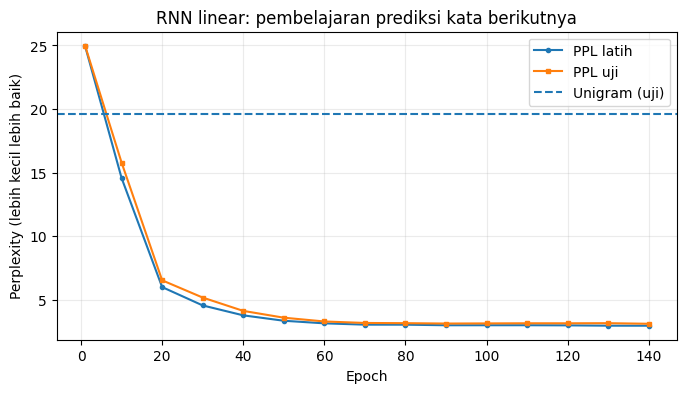

In [13]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
plt.plot(riwayat['epoch'], riwayat['train'], marker='o', markersize=3, label='PPL latih')
plt.plot(riwayat['epoch'], riwayat['uji'], marker='s', markersize=3, label='PPL uji')
plt.axhline(ppl_unigram_uji, linestyle='--', label='Unigram (uji)')
plt.xlabel('Epoch')
plt.ylabel('Perplexity (lebih kecil lebih baik)')
plt.title('RNN linear: pembelajaran prediksi kata berikutnya')
plt.legend()
plt.grid(alpha=.25)
plt.show()

## 16. Menganalisis prediksi token berikutnya 

Buku menampilkan bagaimana model mula-mula memberi prediksi acak, sering beralih pada kata paling sering, kemudian mulai memahami transisi umum semacam `to → the`. Kita akan menampilkan **top-3** prediksi pada setiap prefiks. Prediksi pertama (prefiks kosong) belum memiliki petunjuk, dan token akhir yang ambigu (`the → garden/kitchen/...`) tidak selalu dapat ditentukan dari konteks yang tersedia.

Nilai probabilitas memperjelas ketidakpastian, sedangkan kata dengan peluang terbesar (*argmax*) bukan satu-satunya alternatif yang mungkin.

In [14]:
def top_k_berikutnya(model, awalan, k=3):
    p = model.predict_next(words2indices(awalan))
    indeks = np.argsort(-p)[:k]
    return [(index2word[int(i)], round(float(p[i]), 3)) for i in indeks]

contoh_teks = ['mary', 'moved', 'to', 'the', 'garden']
for t, benar in enumerate(contoh_teks):
    awalan = contoh_teks[:t]
    print(f"Awalan: {' '.join(awalan) or '(kosong)':<26} | Benar: {benar:<9} | Top-3: {top_k_berikutnya(model, awalan)}")

Awalan: (kosong)                   | Benar: mary      | Top-3: [('daniel', 0.263), ('john', 0.259), ('sandra', 0.257)]
Awalan: mary                       | Benar: moved     | Top-3: [('left', 0.239), ('visited', 0.19), ('went', 0.163)]
Awalan: mary moved                 | Benar: to        | Top-3: [('to', 0.987), ('the', 0.004), ('in', 0.003)]
Awalan: mary moved to              | Benar: the       | Top-3: [('the', 0.996), ('to', 0.004), ('in', 0.0)]
Awalan: mary moved to the          | Benar: garden    | Top-3: [('kitchen', 0.257), ('garden', 0.203), ('hallway', 0.194)]


## 17. Menguji sensitivitas terhadap urutan kata

Perhatikan lagi kalimat `red sox defeat yankees` dan urutannya yang diacak. Untuk embedding rata-rata, vektornya **identik**. Pada RNN yang telah mempelajari $R$, dua urutan dari **multiset token yang sama** biasanya menghasilkan vektor yang berbeda. Ini hanya menguji **sensitivitas numerik terhadap urutan**, belum membuktikan model memahami makna atau hubungan sintaksis.

Kita gunakan contoh token dari kosakata korpus pelatihan agar semua embedding pernah dilatih.

In [15]:
def hidden_akhir(model, tokens):
    h = model.start.copy()
    for tok in words2indices(tokens):
        h = h @ model.R + model.E[int(tok)]
    return h

urut_a = ['mary', 'moved', 'to', 'the', 'garden']
urut_b = list(reversed(urut_a))
jarak_rnn = np.linalg.norm(hidden_akhir(model, urut_a) - hidden_akhir(model, urut_b))
E_kata = {w: model.E[i] for i, w in enumerate(kosakata)}
jarak_bow = np.linalg.norm(rerata_embedding(urut_a, E_kata) - rerata_embedding(urut_b, E_kata))
print('Jarak embedding mean (BoW) :', round(float(jarak_bow), 8))
print('Jarak hidden RNN linear    :', round(float(jarak_rnn), 8))
print('Selisih norm(R - I)        :', round(float(np.linalg.norm(model.R-np.eye(HIDDEN_SIZE))), 5))
assert np.allclose(jarak_bow, 0.0)

Jarak embedding mean (BoW) : 0.0
Jarak hidden RNN linear    : 5.09505454
Selisih norm(R - I)        : 2.23212


## 18. Ablasi kecil: apakah mempelajari `R` berpengaruh?

Ablasi mengisolasi sebuah keputusan rancangan. Kita bandingkan dua model yang memakai seed, data, dan jumlah epoch sama:

1. **RNN terlatih:** $R$ boleh berubah melalui BPTT.
2. **Transisi beku:** $R=I$ sepanjang pelatihan; model hanya belajar `E`, `D`, dan `start`.

Dengan $R=I$, representasi tetap berupa penjumlahan embedding, sehingga model kehilangan cara belajar pengaruh **posisi** yang tersedia pada model pertama. Meski demikian, perbedaan PPL dalam satu eksperimen kecil **bukan** estimasi efek kausal yang umum berlaku: butuh lebih dari satu seed, dataset dan rancangan kontrol untuk menyimpulkan keunggulan yang stabil. Ini adalah **tambahan evaluasi asli notebook**, bukan hasil eksperimen yang dilaporkan buku.

In [16]:
model_beku, riwayat_beku = latih_rnn(latih_idx, uji_idx, seed=12,
                                      recurrent_dilatih=False, epochs=EPOCHS)
ppl_beku = perplexity_model(model_beku, uji_idx)
ppl_belajar = perplexity_model(model, uji_idx)
print('Perbandingan PPL holdout:')
print(f'R dilatih  : {ppl_belajar:.3f}')
print(f'R dibekukan: {ppl_beku:.3f}')
print(f'Unigram    : {ppl_unigram_uji:.3f}')
print('Norm R_beku - I:', np.linalg.norm(model_beku.R-np.eye(HIDDEN_SIZE)))
assert np.allclose(model_beku.R, np.eye(HIDDEN_SIZE))

Epoch   1/140: PPL latih=24.959, uji=24.980
Epoch  10/140: PPL latih=18.228, uji=18.927


Epoch  20/140: PPL latih=13.846, uji=14.859
Epoch  30/140: PPL latih=7.822, uji=8.648


Epoch  40/140: PPL latih=5.220, uji=5.727
Epoch  50/140: PPL latih=4.005, uji=4.272


Epoch  60/140: PPL latih=3.485, uji=3.677
Epoch  70/140: PPL latih=3.256, uji=3.420


Epoch  80/140: PPL latih=3.146, uji=3.299
Epoch  90/140: PPL latih=3.080, uji=3.240


Epoch 100/140: PPL latih=3.044, uji=3.213
Epoch 110/140: PPL latih=3.017, uji=3.192
Epoch 120/140: PPL latih=2.999, uji=3.192


Epoch 130/140: PPL latih=2.979, uji=3.189
Epoch 140/140: PPL latih=2.969, uji=3.176
Perbandingan PPL holdout:
R dilatih  : 3.096
R dibekukan: 3.176
Unigram    : 19.629
Norm R_beku - I: 0.0


In [17]:
def kelanjutan_greedy(model, prefix, jumlah_kata=5):
    hasil = list(prefix)
    for _ in range(jumlah_kata):
        probs = model.predict_next(words2indices(hasil))
        hasil.append(index2word[int(probs.argmax())])
    return hasil

for awalan in [['mary'], ['john', 'went'], ['sandra', 'picked']]:
    print('Awalan :', ' '.join(awalan))
    print('Hasil  :', ' '.join(kelanjutan_greedy(model, awalan, jumlah_kata=5)))
    print()

Awalan : mary
Hasil  : mary left the bathroom daniel daniel

Awalan : john went
Hasil  : john went to the kitchen daniel left

Awalan : sandra picked
Hasil  : sandra picked up the apple daniel daniel



## 20. Kesimpulan 

**Ringkasan konsep buku:**

1. **Sekuens panjang variabel** memerlukan mekanisme yang dapat memproses token satu per satu tanpa mengubah ukuran bobot jaringan.
2. **Averaged word embeddings** membentuk representasi ukuran tetap, tetapi tidak mempertahankan urutan; kata yang sama dengan urutan terbalik memberi vektor sama.
3. **Matriks identitas** adalah jembatan konseptual menuju recurrence: ketika $I$ diganti matriks terpelajar $R$, model dapat memanfaatkan informasi urutan.
4. **RNN linear** mempelajari representasi sekuens dengan $h_t=h_{t-1}R+E[x_t]$ serta menggunakan decoder *softmax* untuk memprediksi token berikutnya.
5. **BPTT** menghitung kontribusi kesalahan dari beberapa langkah waktu dan mengakumulasikan gradien pada bobot yang digunakan berulang.
6. **Perplexity** merangkum probabilitas yang diberikan pada kata benar; hasil yang baik harus diperiksa pada data yang belum dilihat selama pelatihan.
7. Representasi dengan dimensi tetap **tidak dapat diasumsikan menyimpan semua informasi** sekuens; apa yang dipertahankan dan dilupakan berkaitan dengan tugas yang dioptimalkan.